In [1]:
# 1 - import thư viện
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cpu")
print("Device:", device)

Device: cpu


In [2]:
# 2 - load data và tiền xử lý
df = pd.read_csv("ecommerce_customer_behavior_dataset.csv")
df["Date"] = pd.to_datetime(df["Date"])

daily = df.groupby("Date").agg(
    Total_Amount=("Total_Amount", "sum"),
    Transactions=("Order_ID", "count"),
    Avg_Order_Value=("Total_Amount", "mean"),
    Quantity=("Quantity", "sum"),
    Avg_Session=("Session_Duration_Minutes", "mean"),
    Avg_Pages=("Pages_Viewed", "mean"),
    Returning_Rate=("Is_Returning_Customer", "mean"),
    Avg_Rating=("Customer_Rating", "mean"),
    Avg_Delivery=("Delivery_Time_Days", "mean")
).reset_index()

daily = daily.sort_values("Date").reset_index(drop=True)

features = [
    "Total_Amount",
    "Transactions",
    "Avg_Order_Value",
    "Quantity",
    "Avg_Session",
    "Avg_Pages",
    "Returning_Rate",
    "Avg_Rating",
    "Avg_Delivery"
]

print("Số ngày:", len(daily))
print("Khoảng thời gian:", daily["Date"].min().date(), "→", daily["Date"].max().date())

Số ngày: 451
Khoảng thời gian: 2023-01-01 → 2024-03-26


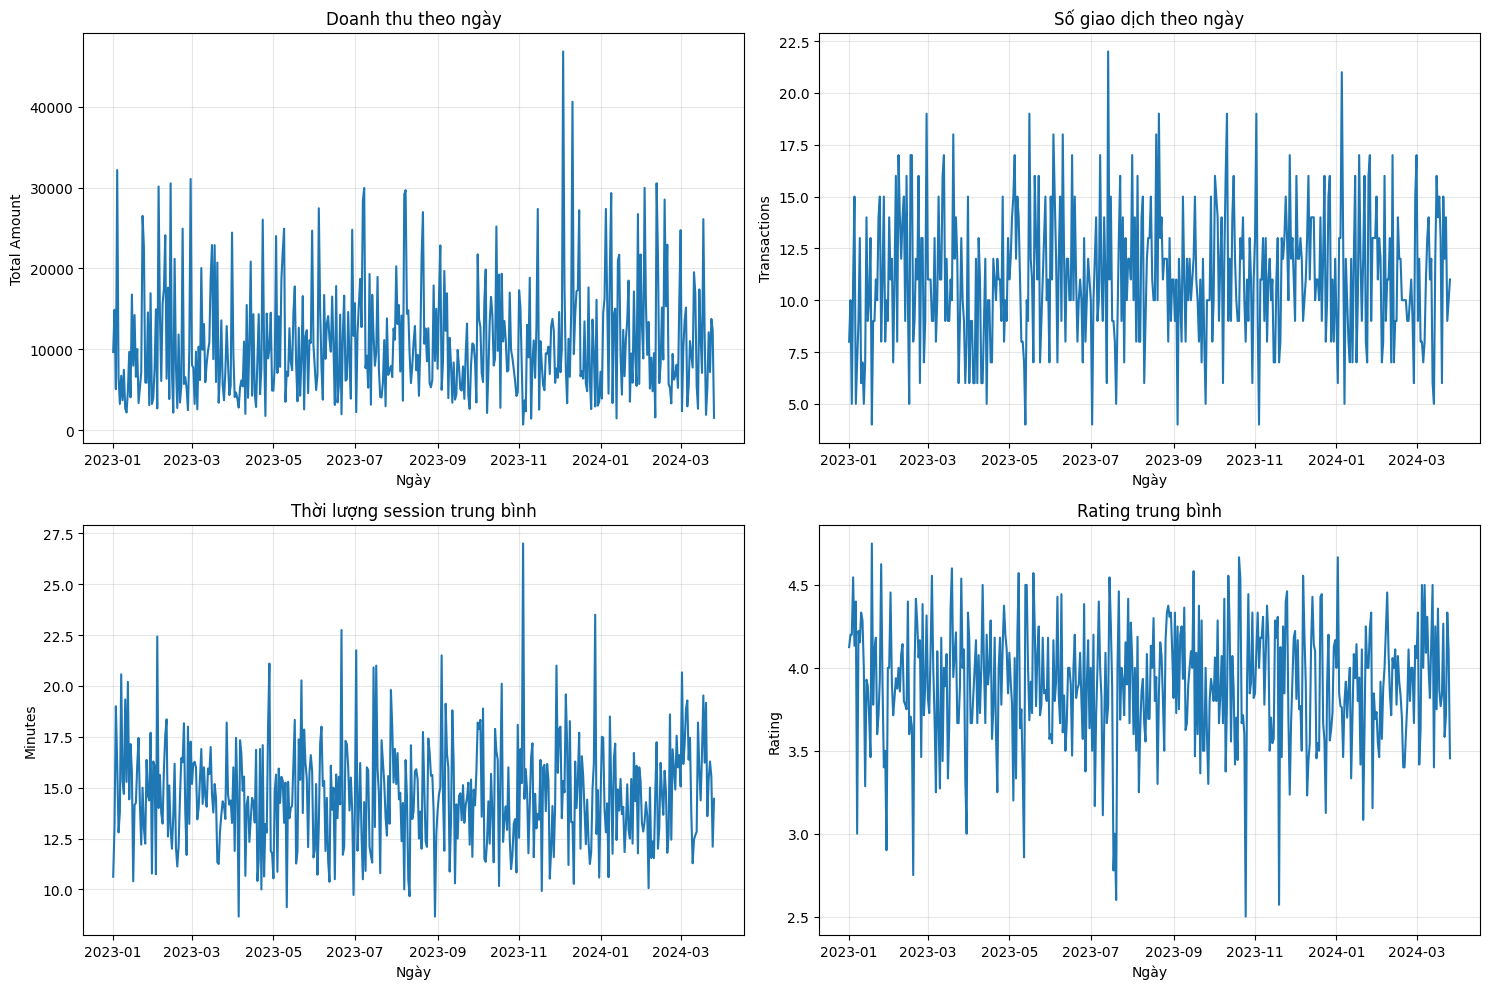

In [3]:
# 3 - visualization tổng quan chuỗi thời gian
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(daily["Date"], daily["Total_Amount"], linewidth=1.5)
axes[0, 0].set_title("Doanh thu theo ngày")
axes[0, 0].set_xlabel("Ngày")
axes[0, 0].set_ylabel("Total Amount")
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(daily["Date"], daily["Transactions"], linewidth=1.5)
axes[0, 1].set_title("Số giao dịch theo ngày")
axes[0, 1].set_xlabel("Ngày")
axes[0, 1].set_ylabel("Transactions")
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(daily["Date"], daily["Avg_Session"], linewidth=1.5)
axes[1, 0].set_title("Thời lượng session trung bình")
axes[1, 0].set_xlabel("Ngày")
axes[1, 0].set_ylabel("Minutes")
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(daily["Date"], daily["Avg_Rating"], linewidth=1.5)
axes[1, 1].set_title("Rating trung bình")
axes[1, 1].set_xlabel("Ngày")
axes[1, 1].set_ylabel("Rating")
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

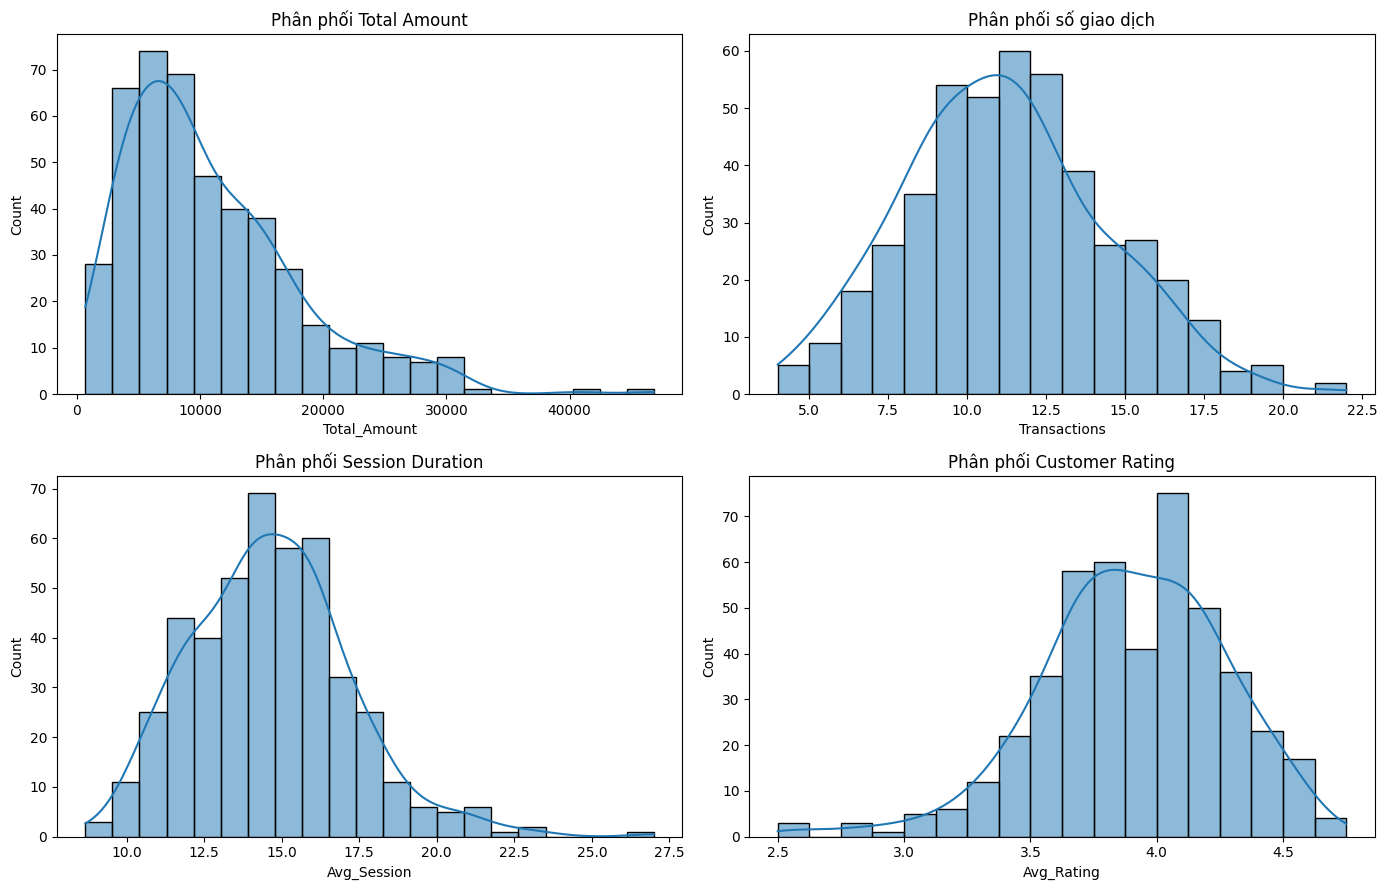

In [4]:
# 4 - visualization phân phối dữ liệu
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(daily["Total_Amount"], kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Phân phối Total Amount")

sns.histplot(daily["Transactions"], kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Phân phối số giao dịch")

sns.histplot(daily["Avg_Session"], kde=True, ax=axes[1, 0])
axes[1, 0].set_title("Phân phối Session Duration")

sns.histplot(daily["Avg_Rating"], kde=True, ax=axes[1, 1])
axes[1, 1].set_title("Phân phối Customer Rating")

plt.tight_layout()
plt.show()

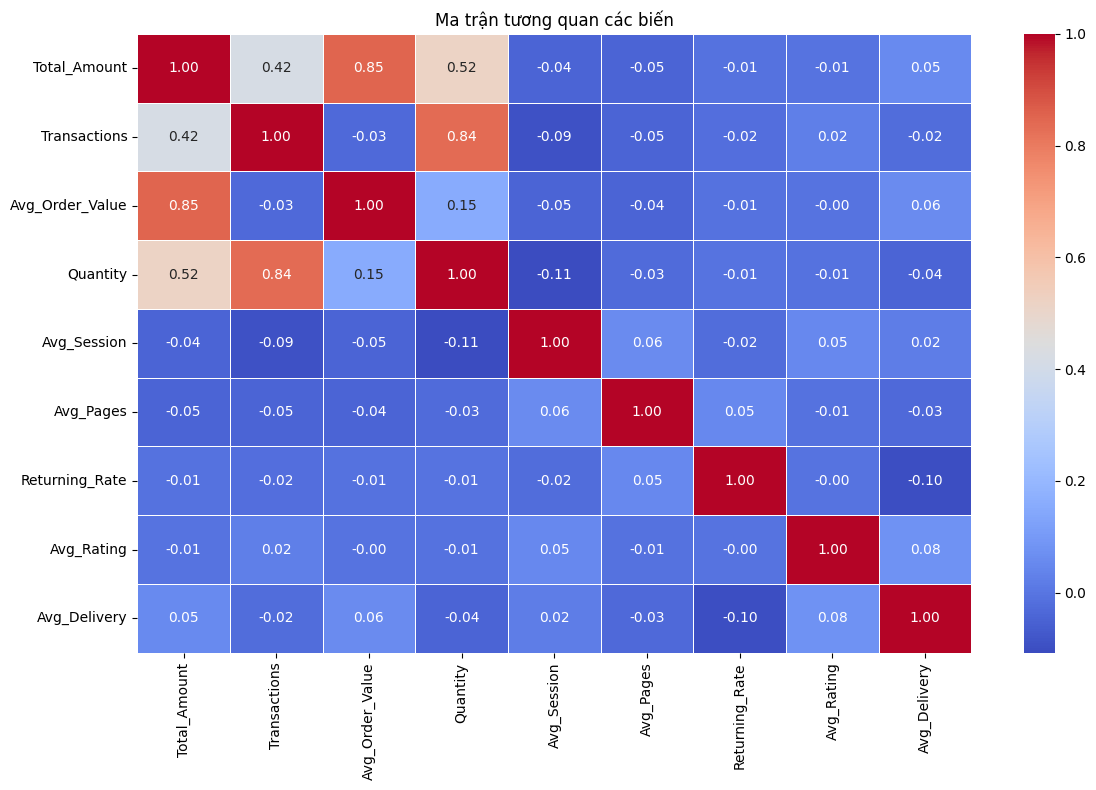

In [5]:
# 5 - visualization ma trận tương quan
plt.figure(figsize=(12, 8))
corr = daily[features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Ma trận tương quan các biến")
plt.tight_layout()
plt.show()

In [6]:
# 6 - chuẩn hóa dữ liệu và tạo sequence
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(daily[features])

sequence_length = 30
target_index = 0

X, y, dates = [], [], []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i])
    y.append(scaled_data[i, target_index])
    dates.append(daily["Date"].iloc[i])

X = np.array(X)
y = np.array(y)
dates = np.array(dates)

train_size = int(len(X) * 0.7)
val_size = int(len(X) * 0.15)

X_train, y_train = X[:train_size], y[:train_size]
X_val, y_val = X[train_size:train_size + val_size], y[train_size:train_size + val_size]
X_test, y_test = X[train_size + val_size:], y[train_size + val_size:]

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (294, 30, 9)
Validation: (63, 30, 9)
Test: (64, 30, 9)


In [7]:
# 7 - tạo DataLoader
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=32,
    shuffle=False
)

val_loader = DataLoader(
    TensorDataset(X_val_tensor, y_val_tensor),
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    TensorDataset(X_test_tensor, y_test_tensor),
    batch_size=32,
    shuffle=False
)

In [8]:
# 8 - xây dựng các mô hình RNN, LSTM và GRU
class RNNModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.rnn = nn.RNN(input_size, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :])

class LSTMModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.lstm = nn.LSTM(input_size, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1, :])

class GRUModel(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.gru = nn.GRU(input_size, 32, batch_first=True)
        self.fc = nn.Linear(32, 1)

    def forward(self, x):
        out, _ = self.gru(x)
        return self.fc(out[:, -1, :])

In [9]:
# 9 - hàm huấn luyện mô hình
def train_model(model, train_loader, val_loader, epochs=50, lr=0.001):
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        train_loss = 0

        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            output = model(X_batch)
            loss = criterion(output, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0

        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                output = model(X_batch)
                val_loss += criterion(output, y_batch).item()

        train_losses.append(train_loss / len(train_loader))
        val_losses.append(val_loss / len(val_loader))

    return train_losses, val_losses

In [10]:
# 10 - huấn luyện 3 mô hình
models = {
    "Simple RNN": RNNModel(len(features)),
    "LSTM": LSTMModel(len(features)),
    "GRU": GRUModel(len(features))
}

histories = {}

for name, model in models.items():
    print(f"Training {name}...")
    histories[name] = train_model(model, train_loader, val_loader)

Training Simple RNN...
Training LSTM...
Training GRU...


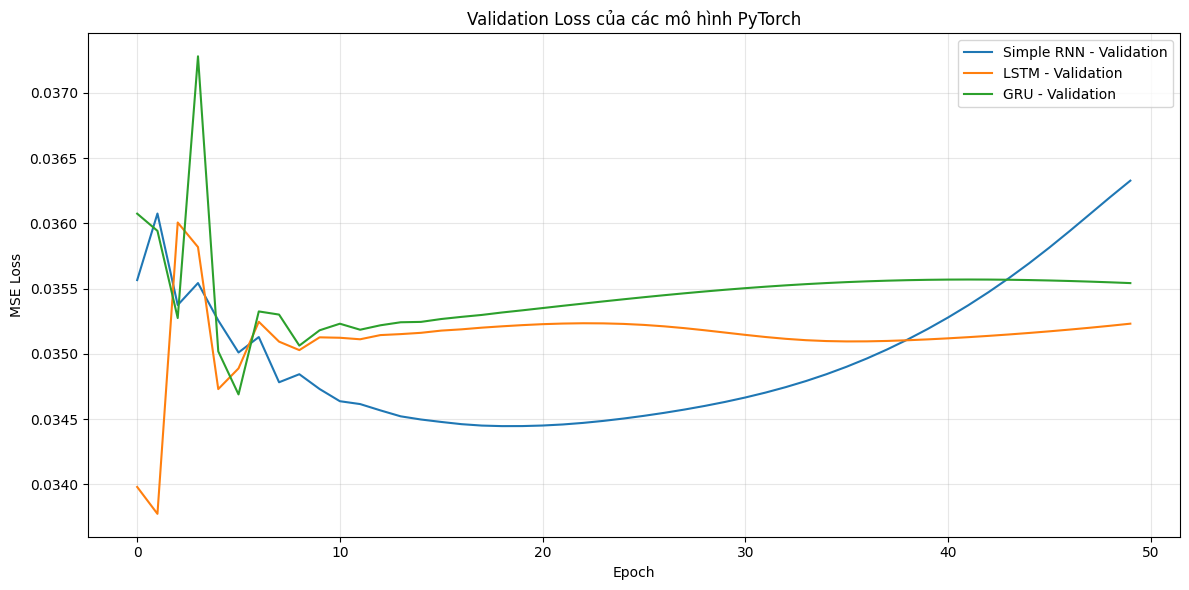

In [11]:
# 11 - visualization learning curves
plt.figure(figsize=(12, 6))

for name, history in histories.items():
    train_loss, val_loss = history
    plt.plot(val_loss, label=f"{name} - Validation")

plt.title("Validation Loss của các mô hình PyTorch")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# 12 - đánh giá các mô hình
def evaluate_model(model, loader):
    model.eval()
    predictions = []
    actuals = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            predictions.extend(model(X_batch).numpy().flatten())
            actuals.extend(y_batch.numpy().flatten())

    predictions = np.array(predictions)
    actuals = np.array(actuals)

    return actuals, predictions

results = []

for name, model in models.items():
    actual, pred = evaluate_model(model, test_loader)

    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    r2 = r2_score(actual, pred)

    results.append([name, mae, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=["Model", "MAE", "RMSE", "R2"]
)

results_df

,Model,MAE,RMSE,R2
0,Simple RNN,0.120667,0.152465,0.090489
1,LSTM,0.124434,0.154508,0.065951
2,GRU,0.122471,0.153224,0.081410


In [13]:
# 13 - chuyển prediction về giá trị Total Amount thực tế
def inverse_target(values):
    temp = np.zeros((len(values), len(features)))
    temp[:, target_index] = values
    return scaler.inverse_transform(temp)[:, target_index]

actual_real = inverse_target(actual)

predictions_real = {}

for name, model in models.items():
    _, pred = evaluate_model(model, test_loader)
    predictions_real[name] = inverse_target(pred)

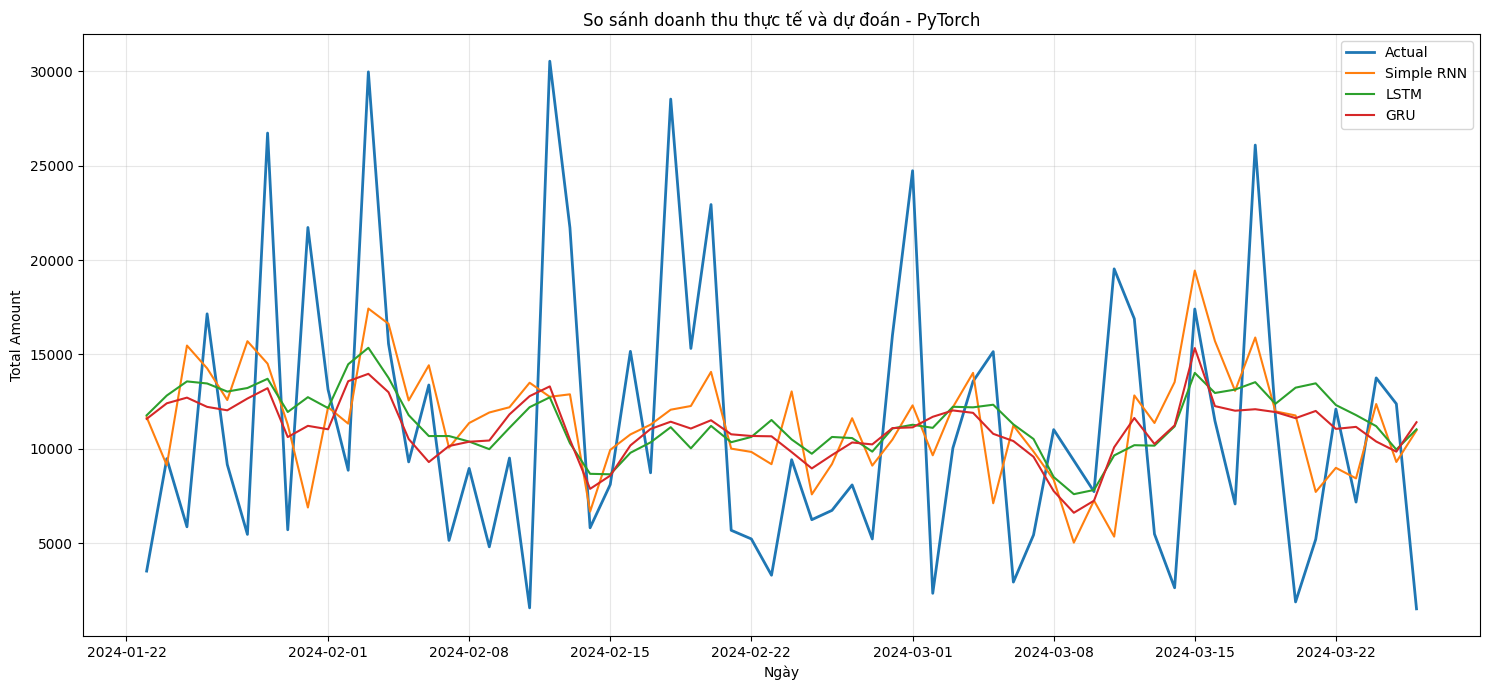

In [14]:
# 14 - visualization Actual và Predicted
plt.figure(figsize=(15, 7))

plt.plot(dates[train_size + val_size:], actual_real, label="Actual", linewidth=2)

for name, pred in predictions_real.items():
    plt.plot(
        dates[train_size + val_size:],
        pred,
        label=name,
        linewidth=1.5
    )

plt.title("So sánh doanh thu thực tế và dự đoán - PyTorch")
plt.xlabel("Ngày")
plt.ylabel("Total Amount")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

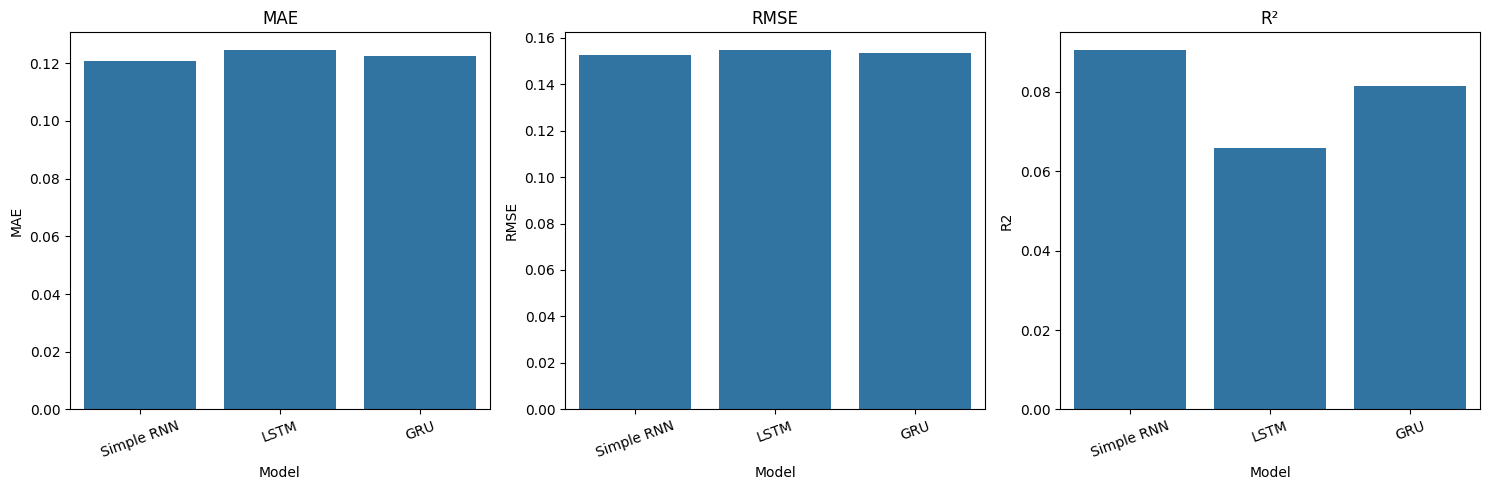

In [15]:
# 15 - visualization so sánh metrics
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.barplot(data=results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(data=results_df, x="Model", y="R2", ax=axes[2])
axes[2].set_title("R²")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [16]:
# 16 - import thư viện Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense, Dropout

tf.random.set_seed(42)
np.random.seed(42)

In [17]:
# 17 - xây dựng các mô hình Keras
def build_rnn():
    model = Sequential([
        SimpleRNN(32, input_shape=(sequence_length, len(features))),
        Dense(1)
    ])
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

def build_lstm():
    model = Sequential([
        LSTM(32, input_shape=(sequence_length, len(features))),
        Dense(1)
    ])
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

def build_gru():
    model = Sequential([
        GRU(32, input_shape=(sequence_length, len(features))),
        Dense(1)
    ])
    model.compile(
        optimizer="adam",
        loss="mse",
        metrics=["mae"]
    )
    return model

In [18]:
# 18 - huấn luyện 3 mô hình Keras
keras_models = {
    "Simple RNN": build_rnn(),
    "LSTM": build_lstm(),
    "GRU": build_gru()
}

keras_histories = {}

for name, model in keras_models.items():
    print(f"Training {name}...")
    keras_histories[name] = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=32,
        verbose=0
    )

C:\Users\vuthu\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training Simple RNN...
Training LSTM...
Training GRU...


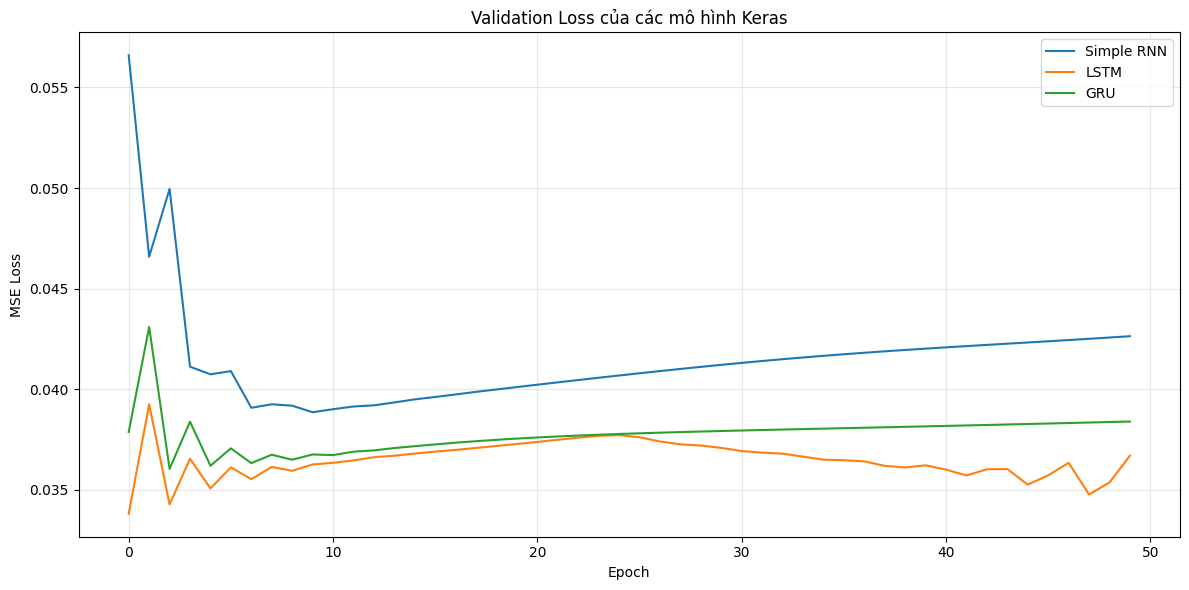

In [19]:
# 19 - visualization learning curves Keras
plt.figure(figsize=(12, 6))

for name, history in keras_histories.items():
    plt.plot(
        history.history["val_loss"],
        label=name
    )

plt.title("Validation Loss của các mô hình Keras")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
# 20 - đánh giá các mô hình Keras
keras_results = []
keras_predictions = {}

for name, model in keras_models.items():
    pred = model.predict(X_test, verbose=0).flatten()

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    keras_predictions[name] = inverse_target(pred)
    keras_results.append([name, mae, rmse, r2])

keras_results_df = pd.DataFrame(
    keras_results,
    columns=["Model", "MAE", "RMSE", "R2"]
)

keras_results_df

,Model,MAE,RMSE,R2
0,Simple RNN,0.123226,0.157589,0.028325
1,LSTM,0.116192,0.157819,0.025485
2,GRU,0.122144,0.155096,0.058828


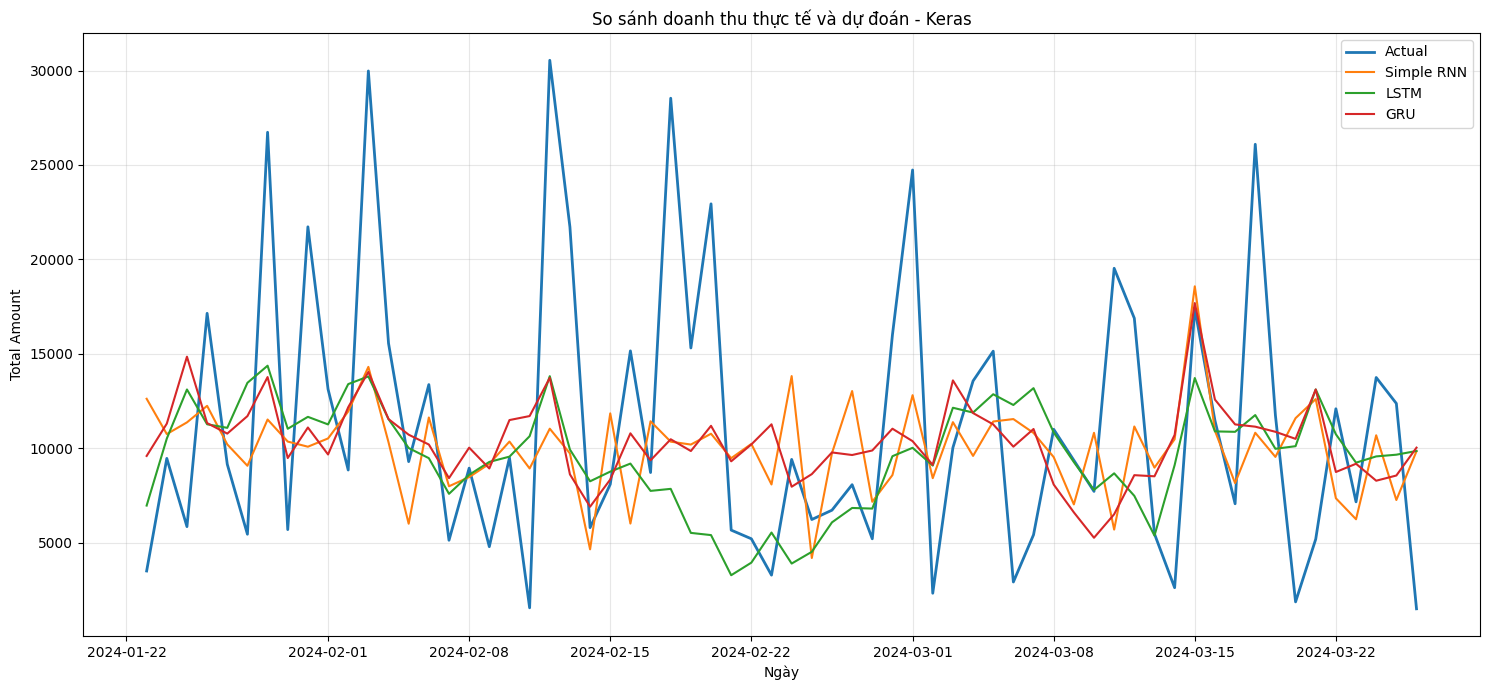

In [21]:
# 21 - visualization Actual và Predicted Keras
plt.figure(figsize=(15, 7))

plt.plot(
    dates[train_size + val_size:],
    actual_real,
    label="Actual",
    linewidth=2
)

for name, pred in keras_predictions.items():
    plt.plot(
        dates[train_size + val_size:],
        pred,
        label=name,
        linewidth=1.5
    )

plt.title("So sánh doanh thu thực tế và dự đoán - Keras")
plt.xlabel("Ngày")
plt.ylabel("Total Amount")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

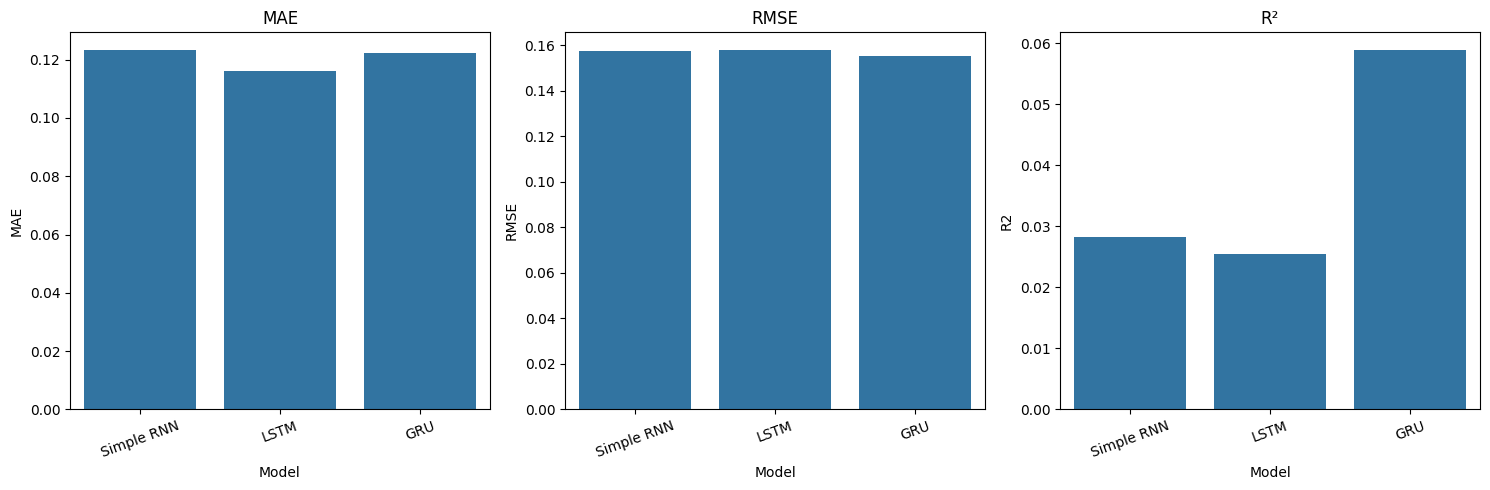

In [22]:
# 22 - visualization metrics Keras
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

sns.barplot(data=keras_results_df, x="Model", y="MAE", ax=axes[0])
axes[0].set_title("MAE")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=keras_results_df, x="Model", y="RMSE", ax=axes[1])
axes[1].set_title("RMSE")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(data=keras_results_df, x="Model", y="R2", ax=axes[2])
axes[2].set_title("R²")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [23]:
# 23 - tổng hợp kết quả PyTorch và Keras
pytorch_compare = results_df.copy()
pytorch_compare["Framework"] = "PyTorch"

keras_compare = keras_results_df.copy()
keras_compare["Framework"] = "Keras"

comparison = pd.concat(
    [pytorch_compare, keras_compare],
    ignore_index=True
)

comparison = comparison[
    ["Framework", "Model", "MAE", "RMSE", "R2"]
]

comparison

,Framework,Model,MAE,RMSE,R2
0,PyTorch,Simple RNN,0.120667,0.152465,0.090489
1,PyTorch,LSTM,0.124434,0.154508,0.065951
2,PyTorch,GRU,0.122471,0.153224,0.081410
3,Keras,Simple RNN,0.123226,0.157589,0.028325
4,Keras,LSTM,0.116192,0.157819,0.025485
5,Keras,GRU,0.122144,0.155096,0.058828


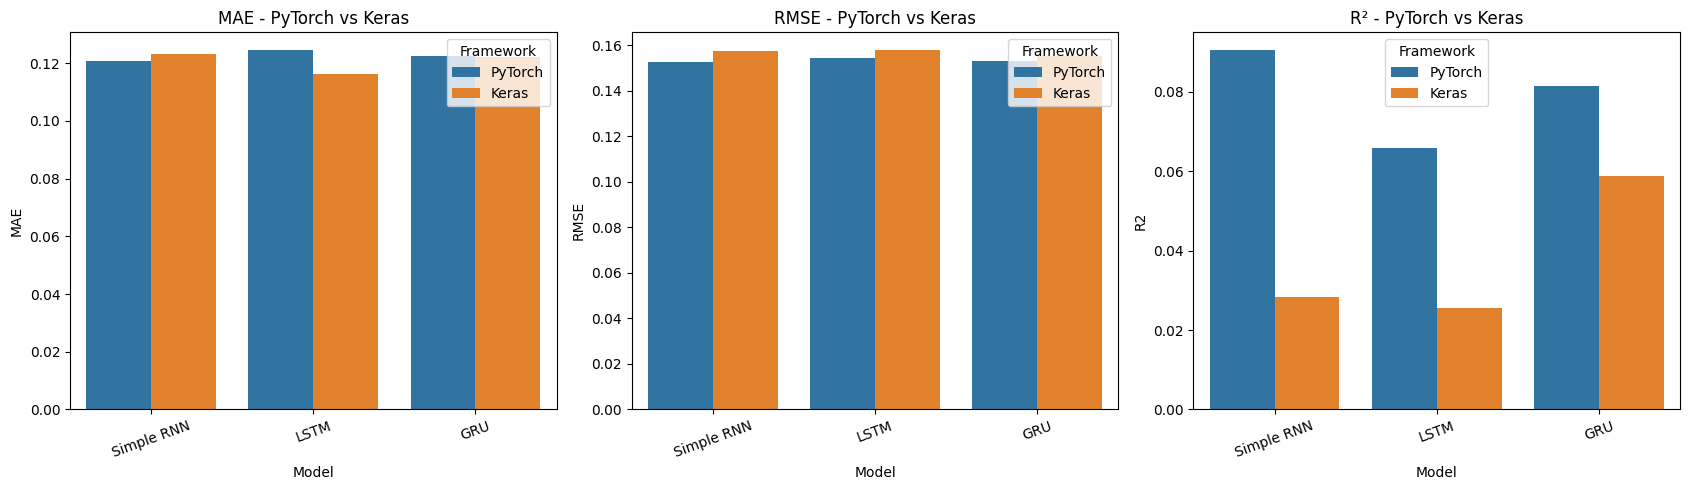

In [24]:
# 24 - visualization so sánh PyTorch và Keras
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="MAE",
    hue="Framework",
    ax=axes[0]
)
axes[0].set_title("MAE - PyTorch vs Keras")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=comparison,
    x="Model",
    y="RMSE",
    hue="Framework",
    ax=axes[1]
)
axes[1].set_title("RMSE - PyTorch vs Keras")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(
    data=comparison,
    x="Model",
    y="R2",
    hue="Framework",
    ax=axes[2]
)
axes[2].set_title("R² - PyTorch vs Keras")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

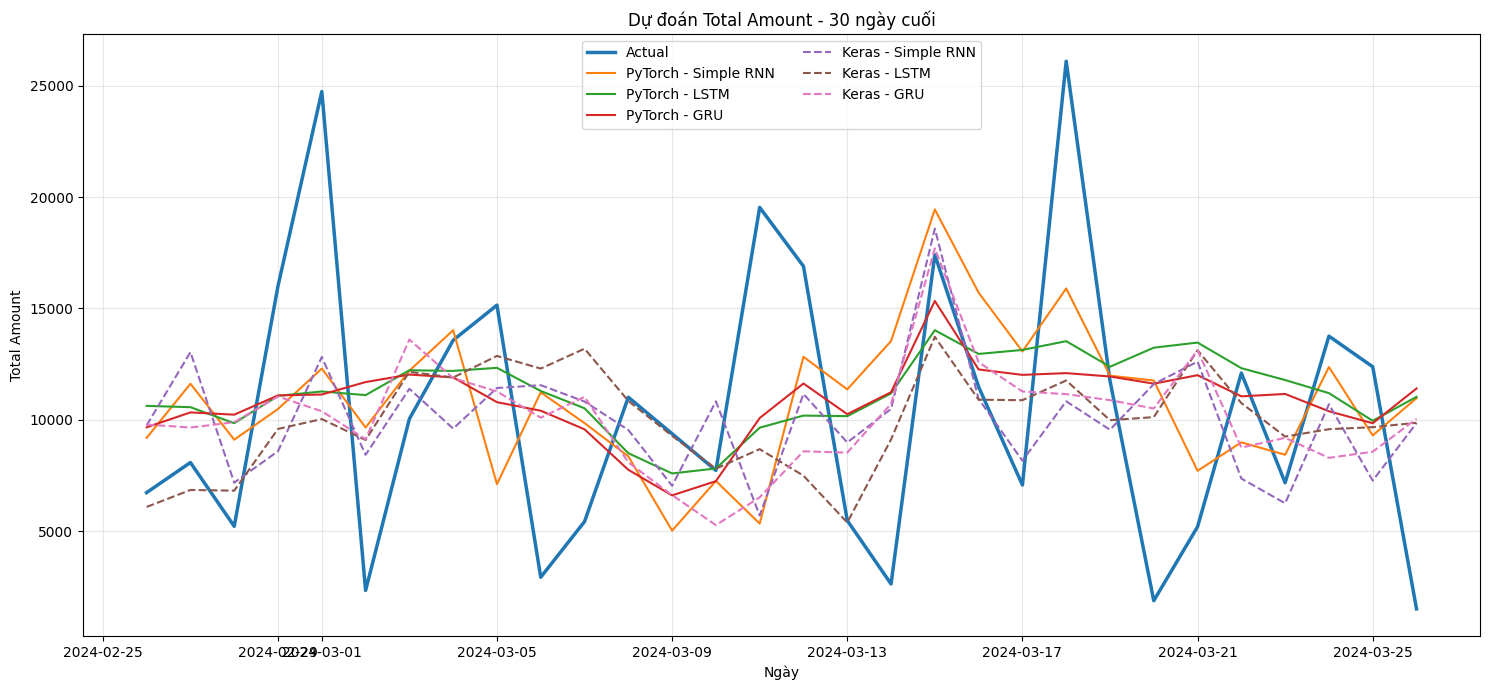

In [25]:
# 25 - visualization dự đoán 30 ngày cuối
last_n = 30

plt.figure(figsize=(15, 7))

plt.plot(
    dates[-last_n:],
    actual_real[-last_n:],
    label="Actual",
    linewidth=2.5
)

for name, pred in predictions_real.items():
    plt.plot(
        dates[-last_n:],
        pred[-last_n:],
        label=f"PyTorch - {name}",
        linewidth=1.5
    )

for name, pred in keras_predictions.items():
    plt.plot(
        dates[-last_n:],
        pred[-last_n:],
        linestyle="--",
        label=f"Keras - {name}",
        linewidth=1.5
    )

plt.title("Dự đoán Total Amount - 30 ngày cuối")
plt.xlabel("Ngày")
plt.ylabel("Total Amount")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()